# 05 Pretrained ResNet18, fine-tuned: RGB versus 13 bands

**Purpose.** Fine-tune a ResNet18 pretrained on ImageNet, once on RGB (3 channels) and once on all 13 bands, with the same split, preprocessing, augmentation and seeds as notebooks 03 and 04. This tests whether the 13-band advantage still holds when the network does not start from zero but from features learned on 1.2 million photos (SQ1). The two inputs differ only in the first layer of the network.

**Functions.** `src/piece_of_crop/resnet.py` (`build_resnet`, `resnet_param_groups`, `IMAGE_SIZE`), `train.py` (`seed_all`, `train_model`, `predict`, `predictions_table`, the same as for the CNN) and `data.py` (`make_loaders`).

**Reads.** `results/split.csv`, `results/band_stats.csv` and the patch cache `data/eurosat_cache.npy`. The ImageNet weights are downloaded by torchvision on first use.

**Saves.** `results/resnet_results.csv`, `results/resnet_history.csv`, six test prediction files `results/predictions/resnet_<input>_seed<n>.csv`, the training curves `results/figures/resnet_<input>_training.png` and the trained weights in `models/` (not in Git; notebook 07 uses them).

## 1. Setup and shared data from notebook 02

All functions come from the installed `piece_of_crop` package. On a Mac the network trains on the GPU through MPS if PyTorch supports it, otherwise on the CPU.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, f1_score
from IPython.display import display

from piece_of_crop import BAND_NAMES, CLASS_NAMES, RGB_BAND_INDICES, read_split, get_cache, make_loaders
from piece_of_crop import IMAGE_SIZE, build_resnet, first_layer_norms, resnet_param_groups
from piece_of_crop import seed_all, train_model, predict, predictions_table

# hyperparameters
SEEDS = (0, 1, 2)
BATCH_SIZE = 32
EPOCHS = 15  # fixed, the cosine schedule runs over all of them
LR_BACKBONE = 1e-4  # pretrained layers
LR_HEAD = 1e-3  # new 10-class head
WEIGHT_DECAY = 1e-4

project_root = Path.cwd().parents[0]
data_dir = project_root / "data" / "EuroSAT_MS"
results_dir = project_root / "results"
figures_dir = results_dir / "figures"
predictions_dir = results_dir / "predictions"
models_dir = project_root / "models"
for folder in [results_dir, figures_dir, predictions_dir, models_dir]:
    folder.mkdir(parents=True, exist_ok=True)

split = read_split(results_dir / "split.csv")
band_stats = pd.read_csv(results_dir / "band_stats.csv")
cache = get_cache(split, data_dir, project_root / "data" / "eurosat_cache.npy")
label_ids = np.arange(len(CLASS_NAMES))
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

print("Project root:", project_root)
print("Device:", device)
print("Patches:", split["split"].value_counts().to_dict())
print("Image size:", IMAGE_SIZE)

Project root: /Users/estellearnander/sem5/AI/piece_of_crop
Device: mps
Patches: {'train': 19159, 'val': 3870, 'test': 3854, 'buffer': 117}
Image size: 224


## 2. The network

ResNet18 is a convolutional network of 18 layers built from residual blocks. Each block adds its input to its output through a "skipping connection", which "makes gradient flow easier" in a deep network (lecture_6ses.8_intro_to_DL-2.pdf, slide 38). Its convolution and pooling layers are the feature extractor and the last fully connected layer is the classifier (lecture_12_finetuning and transfer learning.pdf, slide 4). Trained on ImageNet, the feature extractor has learned edges, textures and parts of objects from 1.2 million photos (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 0). We keep it and replace the 1000-class head with a new linear layer with 10 outputs, because our 10 land-cover classes are not ImageNet's 1000 (lecture_12_finetuning and transfer learning.pdf, slide 8).

**Claim.** For 13 bands, the first layer gets the pretrained red, green and blue filters at the positions of B04, B03 and B02, and filters of zero for the other 10 bands. This makes the 13-band network start exactly as the RGB network.

**Reasons.** The pretrained first layer only has filters for 3 colour channels, so the 10 other bands need new filters. We decided between three ways to start them: at zero, at random, or as copies of the average colour filter. With zeros, the 10 extra bands add nothing at the start, so the 13-band network gives exactly the same output as the RGB network. Any difference after training comes from what the network learns from the extra bands, which is the question of the project.

**Evidence.** The cell below builds both networks from the ImageNet weights and gives them the same patch: the outputs are identical. The course does not cover this step, so we rely on external work. When a pretrained model was extended to multispectral Sentinel-2 input, starting the new channels at zero worked better than the average of the colour filters in all six tasks tested (external: Marimo et al., 2025, "Beyond the Visible: Multispectral Vision-Language Learning for Earth Observation", arXiv:2503.15969, section 6.2). Random filters for the missing channels gave no systematic improvement and made fine-tuning take longer (external: Lacoste et al., 2023, "GEO-Bench: Toward Foundation Models for Earth Monitoring", arXiv:2306.03831, section 6.2.4).

**Warrant.** A comparison only shows the effect of one change if everything else is the same (our rule of changing one thing at a time). Starting both inputs from the same network is the closest we can get to that with a pretrained model.

**Counterargument.** Zero filters must be learned from nothing with the small backbone learning rate, while copies of the colour filters would give the extra bands a head start (external: Corley et al., 2023, arXiv:2305.13456, repeat the colour filters for all bands). The external evidence for zeros also comes from a different kind of model (a vision-language model, not a ResNet). We accept both points. Section 7 checks whether the 13-band network has learned to use the extra bands, and section 8 tests a faster-learning first layer.

In [2]:
# check both networks: 10 outputs, and the 13-band network starts as the RGB network
rgb_check = build_resnet(in_channels=3).eval()
ms_check = build_resnet(in_channels=13).eval()
ms_check.fc.load_state_dict(rgb_check.fc.state_dict())  # same head, so conv1 is the only difference

x = torch.randn(2, 13, IMAGE_SIZE, IMAGE_SIZE)
with torch.no_grad():
    out_rgb = rgb_check(x[:, RGB_BAND_INDICES])  # B04, B03, B02
    out_ms = ms_check(x)
assert out_ms.shape == (2, 10)
print("Largest difference between the RGB and 13-band outputs:", (out_rgb - out_ms).abs().max().item())

for name, check in (("rgb", rgb_check), ("13band", ms_check)):
    n_params = sum(p.numel() for p in check.parameters() if p.requires_grad)
    print(f"{name}: {n_params:,} trainable parameters")
del rgb_check, ms_check

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/estellearnander/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Largest difference between the RGB and 13-band outputs: 4.246830940246582e-07
rgb: 11,181,642 trainable parameters
13band: 11,213,002 trainable parameters


## 3. Training settings

| Setting | Value | Why |
|---|---|---|
| What is trained | every layer (full fine-tuning) | see below |
| Loss | cross-entropy on the logits | the loss for multi-class classification; it expects logits (lecture_5_intro_to_DL.pdf, slide 25) |
| Optimizer | AdamW, learning rate 0.0001 for the pretrained layers and 0.001 for the new head | the backbone gets "a 10× smaller LR than the new head, so we don't destroy what it learned" (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 4, strategy C); "use lower learning rates than training from scratch" (lecture_12_finetuning and transfer learning.pdf, slide 6) |
| Weight decay | 0.0001 | shrinking the weights limits how far fine-tuning can move them, which helps "maintain pre-trained knowledge" (slide 6); the same value as for the CNN, so both deep models are regularised alike |
| Learning-rate schedule | cosine over all batches | large steps early to adapt the pretrained features, small steps at the end so the weights settle (`CosineAnnealingLR`; slide 6) |
| Epochs | 15, fixed | see below |
| Best epoch | lowest validation loss, kept at the end | the test set is used only after this choice (lecture_2_introduction_to_ML.pdf, slide 24) |
| Batch size | 32 | see below |
| Image size | 224 x 224 | see below |
| Normalisation | our per-band training statistics | see below |
| Augmentation | random horizontal and vertical flips, training only | see notebook 02, section 6; the same for the CNN and the ResNet, so augmentation cannot explain a difference between the models |

**Fine-tuning strategy.** We decided between the three strategies of the course: training from scratch, training only a new head on a frozen backbone ("feature extraction"), and full fine-tuning, where every layer is trained (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 4), and the partial unfreezing of the last block from its exercises (section 6). *Claim:* full fine-tuning fits our data best. *Reasons:* the course's guide is that little data calls for feature extraction, while "lots of data" from a "different domain" calls for "full fine-tuning or train from scratch" (same notebook, quiz table). We have about 1,900 training patches per class, inside the 1 to 5 thousand images per class with which a model can be trained from scratch (lecture_12_finetuning and transfer learning.pdf, slide 3), and satellite patches look very different from ImageNet photos. *Evidence:* our CNN trained from scratch already reaches 91.8% (RGB) and 95.4% (13 bands) on test (notebook 04), so we have enough data to train every layer. In the course experiment, full fine-tuning beat feature extraction (90.7% against 79.5% test accuracy) even with only 10 images per class. *Warrant:* features learned on photos must be adapted to satellite images, and only layers that are trained can adapt (slide 5: "let some (or all) of the feature extracting layers be retrained"). *Counterargument:* full fine-tuning needs more compute and has a "higher risk of forgetting/overfitting" (same notebook, section 4). We accept the compute cost and limit the risk with the small backbone learning rate, weight decay and the best validation epoch.

**Epochs: 15 or 30.** We decided between the 30 epochs of notebook 04 and the 15 of the course's fine-tuning notebook. A pretrained network starts from useful features, so it needs fewer epochs than a network trained from scratch: in the course run, the validation loss of full fine-tuning hardly changed after epoch 10 (same notebook, strategy C). Section 5 shows that it holds for our data: the validation loss is flat from about epoch 9, and the best epochs are 10 to 15.

**Batch size: 32 or 128.** We decided between 128 (notebook 04) and 32 (the course's fine-tuning notebook). At 224 x 224 a ResNet18 holds far more activations per patch in memory than the small CNN at 64 x 64, so a batch of 128 is a risk on a laptop GPU. With 32 patches, a batch is under 0.2% of the training set, so the gradient estimate stays noisy (Mathematics for Machine Learning, section 7.1, page 232). RGB and 13 bands use the same batch size, so the comparison between them stays fair.

**Image size: 64, 128 or 224.** *Claim:* we resize the 64 x 64 patches to 224 x 224. *Reasons:* the course preprocesses new images "the same way as the original training" of the pretrained model, which is 224 x 224 for ImageNet (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 1; lecture_12_finetuning and transfer learning.pdf, slide 6, point 1). ResNet18 shrinks its input 32 times, so a 64 x 64 patch would end as a 2 x 2 feature map, while a 224 x 224 patch ends as 7 x 7, the size its last layers were trained on. *Evidence:* on EuroSAT, resizing from 64 to 224 raised the accuracy of frozen ImageNet features with a nearest-neighbour classifier from 82% to 91% for RGB and from 79% to 90% for all bands (external: Corley et al., 2023, "Revisiting pre-trained remote sensing model benchmarks: resizing and normalization matters", arXiv:2305.13456, table 1). *Counterargument:* resizing adds no new information and makes every patch 12 times larger, so training is much slower. These numbers come from frozen features, not fine-tuning, so the gain for a fine-tuned network may be smaller. We accept the cost because the pretrained features work best at the scale they were learned at.

**Normalisation: ImageNet or our own statistics.** *Claim:* we keep the per-band standardisation of notebook 02 instead of the ImageNet mean and standard deviation. *Reasons:* the purpose of the course rule is that the pretrained filters receive inputs on the scale they were trained on. The ImageNet values (for example a mean of 0.485 for red) assume photo brightness between 0 and 1, and bring each colour channel to roughly mean 0 and spread 1. Our raw values are reflectances of about 0 to 10,000, so they would first need an arbitrary rescaling. Standardising each band with our training statistics reaches the same scale directly, and ImageNet has no statistics for 10 of our 13 bands. *Evidence:* on EuroSAT, channel-wise standardisation together with resizing to 224 raised the RGB accuracy of ImageNet features from 66% to 91% compared with dividing by 10,000 (external: Corley et al., 2023, introduction). *Warrant:* a network can only reuse its filters if the inputs are on the scale it learned with. *Counterargument:* the course asks to normalise "with the ImageNet mean/std and not with the Flowers mean/std" (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, quiz question 1), and slide 6 asks for the same preprocessing as the original data. We accept that we deviate from the course method, but not from its goal: the deviation is needed because our data are not photos.

## 4. Train RGB and 13-band networks with three seeds

For every seed the data loaders are created again, so the shuffling and augmentation follow that seed. After training, each network is evaluated on validation and test with the weights of its best epoch. The training accuracy is the one measured in the training loop at that epoch. The time of each run is recorded, because compute is part of the cost of using 13 bands and larger models. The test predictions use the team format from `predictions_table`, the same as notebooks 03 and 04.

In [3]:
history_runs = []
result_rows = []
test_files = split.loc[split["split"].eq("test"), "file"]
test_labels = split.loc[split["split"].eq("test"), "label"].to_numpy()

# train every model, 2 inputs x 3 seeds
for input_type, n_channels in (("rgb", 3), ("13band", 13)):
    for seed in SEEDS:
        print(f"\n=== ResNet18 {input_type}, seed {seed} ===")
        seed_all(seed)
        loaders = make_loaders(split, cache, band_stats, input_type, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE)

        model = build_resnet(in_channels=n_channels, num_classes=len(CLASS_NAMES)).to(device)
        optimizer = torch.optim.AdamW(resnet_param_groups(model, LR_BACKBONE, LR_HEAD), weight_decay=WEIGHT_DECAY)
        # the model ends with the weights of the epoch with the lowest val loss
        start = time.time()
        history, best_epoch = train_model(model, loaders["train"], loaders["val"], optimizer, EPOCHS, device)
        minutes = (time.time() - start) / 60
        print(f"Training took {minutes:.1f} minutes")

        run = pd.DataFrame(history)
        run["epoch"] = np.arange(1, EPOCHS + 1)
        run["input"], run["seed"] = input_type, seed
        history_runs.append(run)
        torch.save(model.state_dict(), models_dir / f"resnet_{input_type}_seed{seed}.pt")

        # train accuracy comes from the training loop at the best epoch
        result_rows.append({"model": "ResNet18", "input": input_type, "seed": seed, "split": "train",
            "accuracy": history["train_acc"][best_epoch - 1], "best_epoch": best_epoch, "minutes": minutes})
        # best epoch is picked on validation, test set is only used from here
        for subset in ("val", "test"):
            y_true, proba = predict(model, loaders[subset], device)
            y_pred = proba.argmax(axis=1)
            result_rows.append({"model": "ResNet18", "input": input_type, "seed": seed, "split": subset,
                "accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro"),
                "best_epoch": best_epoch, "minutes": minutes})
            # save the test predictions to csv
            if subset == "test":
                assert np.array_equal(y_true, test_labels)  # predictions are in split order
                predictions_table(test_files, y_true, proba).to_csv(
                    predictions_dir / f"resnet_{input_type}_seed{seed}.csv", index=False)


resnet_history = pd.concat(history_runs, ignore_index=True)
resnet_results = pd.DataFrame(result_rows)

resnet_history.to_csv(results_dir / "resnet_history.csv", index=False)
resnet_results.to_csv(results_dir / "resnet_results.csv", index=False)


=== ResNet18 rgb, seed 0 ===
Epoch 1: train loss=0.205 acc=0.933 | validation loss=0.067 acc=0.982
Epoch 2: train loss=0.107 acc=0.965 | validation loss=0.094 acc=0.970
Epoch 3: train loss=0.087 acc=0.972 | validation loss=0.059 acc=0.980
Epoch 4: train loss=0.061 acc=0.979 | validation loss=0.062 acc=0.982
Epoch 5: train loss=0.052 acc=0.984 | validation loss=0.058 acc=0.982
Epoch 6: train loss=0.043 acc=0.987 | validation loss=0.055 acc=0.986
Epoch 7: train loss=0.029 acc=0.991 | validation loss=0.048 acc=0.986
Epoch 8: train loss=0.022 acc=0.993 | validation loss=0.050 acc=0.985
Epoch 9: train loss=0.019 acc=0.994 | validation loss=0.048 acc=0.986
Epoch 10: train loss=0.011 acc=0.997 | validation loss=0.053 acc=0.986
Epoch 11: train loss=0.008 acc=0.997 | validation loss=0.041 acc=0.989
Epoch 12: train loss=0.006 acc=0.998 | validation loss=0.040 acc=0.988
Epoch 13: train loss=0.004 acc=0.999 | validation loss=0.036 acc=0.990
Epoch 14: train loss=0.003 acc=0.999 | validation loss=0

## 5. Training curves

Training and validation loss per epoch for each seed (left) and validation accuracy (right). The training loss is measured on augmented patches while the network is still changing during the epoch, so it is not directly comparable with the validation loss, and the training accuracy in section 6 is a rough check for overfitting, not an exact score.

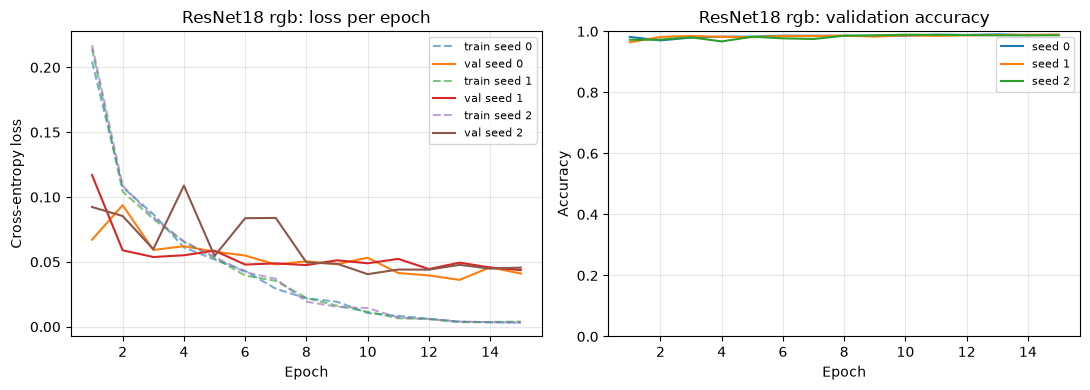

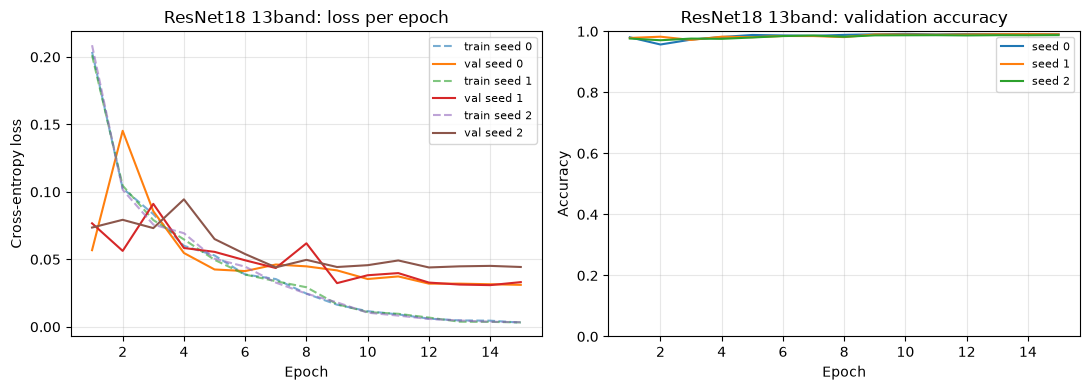

Best epoch (lowest validation loss) and training time for each network:


,input,seed,best_epoch,minutes
2,rgb,0,13,58.5
5,rgb,1,15,48.9
8,rgb,2,10,55.6
11,13band,0,15,53.2
14,13band,1,14,52.0
17,13band,2,12,57.5


In [4]:
# plot the loss and accuracy for every epoch
for input_type in ("rgb", "13band"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for seed in SEEDS:
        run = resnet_history[(resnet_history["input"] == input_type) & (resnet_history["seed"] == seed)]
        axes[0].plot(run["epoch"], run["train_loss"], ls="--", alpha=0.6, label=f"train seed {seed}")
        axes[0].plot(run["epoch"], run["val_loss"], label=f"val seed {seed}")
        axes[1].plot(run["epoch"], run["val_acc"], label=f"seed {seed}")

    axes[0].set(title=f"ResNet18 {input_type}: loss per epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(title=f"ResNet18 {input_type}: validation accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(figures_dir / f"resnet_{input_type}_training.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Best epoch (lowest validation loss) and training time for each network:")
display(resnet_results[resnet_results["split"].eq("test")][["input", "seed", "best_epoch", "minutes"]].round(1))

**Claim.** Every network converged within the 15 epochs, and fine-tuning overfits a little more than the CNN trained from scratch.

**Reasons.** The pretrained features are useful from the first epoch, so the networks reach a high validation accuracy at once and then only refine it. With 11 million weights the network can fit its training patches almost perfectly.

**Evidence.** Mean validation accuracy over the three seeds is already 97.3% (RGB) and 97.8% (13 bands) after epoch 1. The mean validation loss falls from 0.092 (RGB) and 0.069 (13 bands) after epoch 1 to about 0.049 and 0.040 at epoch 9 and changes little after that (0.043 and 0.036 at epoch 15). The best epochs lie between 10 and 15. At the best epoch, the training accuracy is 99.8% (RGB) and 99.9% (13 bands), against 98.9% on validation and 97.2% on test for both inputs.

**Warrant.** A model overfits when its training score is far above its score on new data (lecture_2_introduction_to_ML.pdf, slide 20). The gap between training and test is 2.6 to 2.7 points here, against at most 1.2 points between training and validation for the CNN (notebook 04). This fits the course's warning that full fine-tuning has a "higher risk of forgetting/overfitting" (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 4).

**Counterargument.** The validation loss of some seeds rises for one or two epochs (for example 13 bands at epoch 2) before it falls again. These are single bumps while the learning rate is still high, and keeping the epoch with the lowest validation loss means they do not reach the final network. The overfitting is modest: test accuracy is still 5 points above the RGB CNN.

## 6. Results: RGB versus 13 bands

Mean and standard deviation over the three seeds, for training, validation and test. The per-class reports show seed 0 only; the other seeds are in the prediction files.

In [5]:
# mean and std over the 3 seeds
summary = resnet_results.groupby(["input", "split"], sort=False)[["accuracy", "macro_f1"]]
display(summary.agg(["mean", "std"]).round(4))

# per class report, only for seed 0
for input_type in ("rgb", "13band"):
    pred = pd.read_csv(predictions_dir / f"resnet_{input_type}_seed0.csv")
    print(f"\nPer class test report: {input_type}, seed 0")
    print(classification_report(pred["y_true"], pred["y_pred"], labels=label_ids,
          target_names=list(CLASS_NAMES), zero_division=0))

accuracy         macro_f1        
                 mean     std     mean     std
input  split                                  
rgb    train   0.9977  0.0021      NaN     NaN
       val     0.9892  0.0006   0.9886  0.0008
       test    0.9719  0.0020   0.9713  0.0020
13band train   0.9989  0.0006      NaN     NaN
       val     0.9893  0.0024   0.9885  0.0027
       test    0.9718  0.0019   0.9712  0.0019


Per class test report: rgb, seed 0
                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.99      0.98       429
              Forest       0.99      1.00      1.00       429
HerbaceousVegetation       0.89      0.92      0.91       428
             Highway       0.99      0.99      0.99       358
          Industrial       1.00      0.99      1.00       357
             Pasture       0.98      0.98      0.98       286
       PermanentCrop       0.91      0.85      0.88       353
         Residential       1.00      1.00      1.00       428
               River       0.99      0.99      0.99       357
             SeaLake       1.00      1.00      1.00       429

            accuracy                           0.97      3854
           macro avg       0.97      0.97      0.97      3854
        weighted avg       0.97      0.97      0.97      3854


Per class test report: 13band, seed 0
                      precision    recall  f1-score   

**Claim.** With the pretrained ResNet, the 13 bands give no gain in accuracy: both inputs reach 97.2% on test. The two inputs do, however, make different mistakes.

**Reasons.** Starting from ImageNet filters, the RGB network already reaches 97.2%. Its remaining mistakes are mostly between PermanentCrop and HerbaceousVegetation, and the 13-band network makes these almost as often. Sections 7 to 9 show that the 13-band network does use the extra bands, so the missing gain is not because they were ignored.

**Evidence.** Test accuracy 0.9719 (RGB) against 0.9718 (13 bands), macro-F1 0.9713 against 0.9712, each with a standard deviation of 0.002 over three seeds. Averaged over the seeds, the per-class F1 scores differ by at most 1.7 points (Forest: 0.995 against 0.978). About 70% of the misclassified test patches are wrong for both inputs. PermanentCrop predicted as HerbaceousVegetation is the most common mistake for both (39.3 patches per seed). The other mistakes shift: HerbaceousVegetation predicted as PermanentCrop drops from 24.7 to 12.7 patches per seed with 13 bands, while HerbaceousVegetation predicted as Forest rises from 3.7 to 18.3. PermanentCrop remains the weakest class for both inputs (F1 0.88 and 0.89).

**Warrant.** A difference of 0.01 points against a seed spread of 0.2 points is no difference. Because the test patches were not used for training or for choosing the best epoch (lecture_2_introduction_to_ML.pdf, slide 24), this is what the networks would do on new parcels.

**Counterargument 1: the result may depend on how the extra bands were added.** Their filters started at zero and were trained with the small backbone learning rate. Section 8 retrains with a faster first layer to test this; section 9 shows that it does not change the conclusion.

**Counterargument 2: equal accuracy does not mean equal cost.** Whether the shift from PermanentCrop errors to Forest errors helps an insurer depends on what each confusion costs: mistaking grassland for a permanent crop changes the insured crop, while mistaking it for forest changes whether the land is farmed at all. Notebook 06 weighs the errors with the insurer cost table.

## 7. Does the 13-band ResNet use the extra bands?

Two checks on the three saved 13-band networks, without retraining:

1. **The size of the first-layer filters per band.** Each band has 64 filters of 7 x 7 weights in the first layer; their size (L2 norm) shows how strongly the network responds to that band. The colour bands started with the ImageNet filters and the other 10 bands at zero.
2. **Test accuracy without the extra bands.** We set the 10 extra bands to 0, the training mean after normalisation, so they carry no information, and predict the test set again. If the accuracy barely drops, the network does not depend on these bands.

Size of the first-layer filters per band (mean and std over the seeds):


,B01,B02,B03,B04,B05,B06,B07,B08,B09,B10,B11,B12,B8A
mean,0.182,5.650,8.662,7.219,0.173,0.144,0.163,0.200,0.153,0.129,0.255,0.191,0.151
std,0.006,0.004,0.004,0.004,0.015,0.011,0.010,0.007,0.002,0.007,0.007,0.014,0.008


,seed,test_accuracy,without_extra_bands,drop
0,0,0.9730,0.9094,0.0636
1,1,0.9728,0.8672,0.1056
2,2,0.9696,0.9056,0.0641


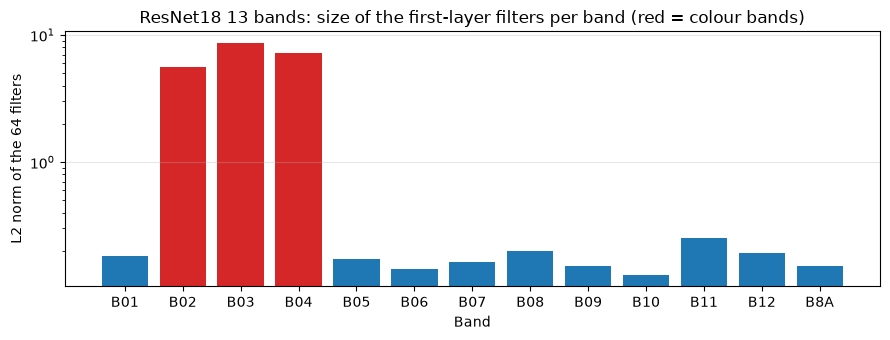

In [2]:
extra_bands = [b for b in range(13) if b not in RGB_BAND_INDICES]
test_loader_13 = make_loaders(split, cache, band_stats, "13band", batch_size=BATCH_SIZE, image_size=IMAGE_SIZE)["test"]


def band_use(file_name):
    """First-layer filter size per band, and test accuracy with and without the extra bands."""
    model = build_resnet(in_channels=13, num_classes=len(CLASS_NAMES), pretrained=False)
    model.load_state_dict(torch.load(models_dir / file_name, map_location="cpu"))
    model.to(device)
    y_true, proba = predict(model, test_loader_13, device)
    _, proba_without = predict(model, test_loader_13, device, zero_bands=extra_bands)
    return first_layer_norms(model), accuracy_score(y_true, proba.argmax(1)), accuracy_score(y_true, proba_without.argmax(1))


norm_rows, use_rows = [], []
for seed in SEEDS:
    norms, acc_all, acc_without = band_use(f"resnet_13band_seed{seed}.pt")
    norm_rows.append(norms)
    use_rows.append({"seed": seed, "test_accuracy": acc_all, "without_extra_bands": acc_without})

filter_sizes = pd.DataFrame(norm_rows, columns=BAND_NAMES)
band_use_table = pd.DataFrame(use_rows)
band_use_table["drop"] = band_use_table["test_accuracy"] - band_use_table["without_extra_bands"]
print("Size of the first-layer filters per band (mean and std over the seeds):")
display(filter_sizes.agg(["mean", "std"]).round(3))
display(band_use_table.round(4))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(BAND_NAMES, filter_sizes.mean(), color=["tab:red" if b in RGB_BAND_INDICES else "tab:blue" for b in range(13)])
ax.set(title="ResNet18 13 bands: size of the first-layer filters per band (red = colour bands)",
       xlabel="Band", ylabel="L2 norm of the 64 filters", yscale="log")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(figures_dir / "resnet_13band_first_layer.png", dpi=150, bbox_inches="tight")
plt.show()


**Claim.** The 13-band network depends on the extra bands, even though their first-layer filters stayed small.

**Reasons.** The size of a filter is not the same as its effect. The first layer is followed by BatchNorm and the rest of the network, which adjust to everything the first layer passes on, so small filters can still shift the signals that later layers rely on.

**Evidence.** The filters of the 10 extra bands grew from zero to a size of 0.13 to 0.26, while the colour filters stayed at their ImageNet size (5.65 for B02, 8.66 for B03, 7.22 for B04), 20 to 70 times larger. Yet setting the extra bands to 0 lowers test accuracy from 97.3%, 97.3% and 97.0% to 90.9%, 86.7% and 90.6%: a drop of 6.4 to 10.6 points.

**Warrant.** If a network ignored an input, removing that input would not change its predictions. A drop of 6 to 11 points means the predictions of the 13-band network rely on the extra bands.

**Counterargument.** No training patch had its extra bands at exactly 0, so the test patches without them are unlike anything the network has seen, and part of the drop comes from this unfamiliar input rather than from lost information. The check therefore shows that the network depends on the extra bands, not that they add information beyond RGB: the RGB network reaches the same 97.2% without them. Whether more use of the extra bands would raise accuracy is what section 8 tests.

## 8. Check: a first layer that learns at the rate of a new layer

**Claim.** If the extra bands were ignored because of how we trained the first layer, a first layer with the learning rate of the new head (0.001 instead of 0.0001) should learn to use them. We retrain the three 13-band networks with only this change.

**Reasons.** The backbone gets a 10 times smaller learning rate so that fine-tuning does "not destroy what it learned" (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 4, strategy C). The filters for the 10 extra bands started at zero and had learned nothing, so this reason does not apply to them: they are new weights, like the head. A learning rate cannot be set per band inside one layer, so the whole first layer gets 0.001; the rest of the backbone keeps 0.0001.

**Warrant.** A comparison only shows the effect of one change if everything else stays the same, so the split, seeds, epochs, augmentation and the rest of the optimizer are unchanged.

**Counterargument.** The pretrained colour filters in the first layer now also learn faster and may lose some of what they learned on ImageNet. And the RGB networks keep the original setting, so if this check improves the 13-band networks, an RGB network with the same first-layer rate might improve too. We accept both: this is a check of whether our setup caused the result of section 6, not a new main comparison. Section 9 interprets it with this in mind.

The results are saved after every network, so an interrupted run keeps the finished networks. The files use a separate name (`resnet_13band_firstlayer_...`) so notebook 06 still reads the main comparison.

In [3]:
LR_FIRST_LAYER = 1e-3  # the head's learning rate, for conv1 only
test_files = split.loc[split["split"].eq("test"), "file"]
test_labels = split.loc[split["split"].eq("test"), "label"].to_numpy()
check_histories, check_rows = [], []

for seed in SEEDS:
    print(f"\n=== ResNet18 13band, first layer at {LR_FIRST_LAYER}, seed {seed} ===")
    seed_all(seed)
    loaders = make_loaders(split, cache, band_stats, "13band", batch_size=BATCH_SIZE, image_size=IMAGE_SIZE)

    model = build_resnet(in_channels=13, num_classes=len(CLASS_NAMES)).to(device)
    groups = resnet_param_groups(model, LR_BACKBONE, LR_HEAD, lr_first_layer=LR_FIRST_LAYER)
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    start = time.time()
    history, best_epoch = train_model(model, loaders["train"], loaders["val"], optimizer, EPOCHS, device)
    minutes = (time.time() - start) / 60
    print(f"Training took {minutes:.1f} minutes")
    torch.save(model.state_dict(), models_dir / f"resnet_13band_firstlayer_seed{seed}.pt")

    run = pd.DataFrame(history)
    run["epoch"] = np.arange(1, EPOCHS + 1)
    run["seed"] = seed
    check_histories.append(run)
    check_rows.append({"model": "ResNet18 first layer 1e-3", "input": "13band", "seed": seed, "split": "train",
        "accuracy": history["train_acc"][best_epoch - 1], "best_epoch": best_epoch, "minutes": minutes})
    for subset in ("val", "test"):
        y_true, proba = predict(model, loaders[subset], device)
        y_pred = proba.argmax(axis=1)
        check_rows.append({"model": "ResNet18 first layer 1e-3", "input": "13band", "seed": seed, "split": subset,
            "accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "best_epoch": best_epoch, "minutes": minutes})
        if subset == "test":
            assert np.array_equal(y_true, test_labels)  # predictions are in split order
            predictions_table(test_files, y_true, proba).to_csv(
                predictions_dir / f"resnet_13band_firstlayer_seed{seed}.csv", index=False)

    # save after every network, so a crash keeps the finished ones
    pd.concat(check_histories, ignore_index=True).to_csv(results_dir / "resnet_firstlayer_history.csv", index=False)
    pd.DataFrame(check_rows).to_csv(results_dir / "resnet_firstlayer_results.csv", index=False)

check_results = pd.DataFrame(check_rows)



=== ResNet18 13band, first layer at 0.001, seed 0 ===
Epoch 1: train loss=0.243 acc=0.920 | validation loss=0.116 acc=0.964
Epoch 2: train loss=0.122 acc=0.960 | validation loss=0.136 acc=0.962
Epoch 3: train loss=0.102 acc=0.968 | validation loss=0.089 acc=0.969
Epoch 4: train loss=0.069 acc=0.978 | validation loss=0.052 acc=0.984
Epoch 5: train loss=0.064 acc=0.980 | validation loss=0.057 acc=0.984
Epoch 6: train loss=0.052 acc=0.983 | validation loss=0.073 acc=0.979
Epoch 7: train loss=0.040 acc=0.986 | validation loss=0.054 acc=0.981
Epoch 8: train loss=0.031 acc=0.990 | validation loss=0.042 acc=0.986
Epoch 9: train loss=0.022 acc=0.993 | validation loss=0.039 acc=0.987
Epoch 10: train loss=0.015 acc=0.995 | validation loss=0.043 acc=0.989
Epoch 11: train loss=0.010 acc=0.997 | validation loss=0.041 acc=0.988
Epoch 12: train loss=0.008 acc=0.997 | validation loss=0.039 acc=0.989
Epoch 13: train loss=0.007 acc=0.998 | validation loss=0.038 acc=0.990
Epoch 14: train loss=0.004 acc=

## 9. Results of the check

The test scores of the three versions side by side, and the same two band checks as in section 7 for the new networks.

In [4]:
# test scores: main RGB, main 13 bands, 13 bands with the faster first layer
main_results = pd.read_csv(results_dir / "resnet_results.csv")
check_results = pd.read_csv(results_dir / "resnet_firstlayer_results.csv")
comparison = pd.concat([main_results.assign(version="main"), check_results.assign(version="first layer 1e-3")])
comparison = comparison[comparison["split"].eq("test")]
display(comparison.groupby(["version", "input"], sort=False)[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(4))

# band checks for the new networks
check_norms, check_use = [], []
for seed in SEEDS:
    norms, acc_all, acc_without = band_use(f"resnet_13band_firstlayer_seed{seed}.pt")
    check_norms.append(norms)
    check_use.append({"seed": seed, "test_accuracy": acc_all, "without_extra_bands": acc_without})

check_filter_sizes = pd.DataFrame(check_norms, columns=BAND_NAMES)
check_use_table = pd.DataFrame(check_use)
check_use_table["drop"] = check_use_table["test_accuracy"] - check_use_table["without_extra_bands"]
print("Size of the first-layer filters per band, first layer at 1e-3:")
display(check_filter_sizes.agg(["mean", "std"]).round(3))
display(check_use_table.round(4))

# per class report, only for seed 0
pred = pd.read_csv(predictions_dir / "resnet_13band_firstlayer_seed0.csv")
print("Per class test report: 13band with first layer at 1e-3, seed 0")
print(classification_report(pred["y_true"], pred["y_pred"], labels=label_ids,
      target_names=list(CLASS_NAMES), zero_division=0))


accuracy         macro_f1        
                            mean     std     mean     std
version          input                                   
main             rgb      0.9719  0.0020   0.9713  0.0020
                 13band   0.9718  0.0019   0.9712  0.0019
first layer 1e-3 13band   0.9687  0.0024   0.9686  0.0025

Size of the first-layer filters per band, first layer at 1e-3:


,B01,B02,B03,B04,B05,B06,B07,B08,B09,B10,B11,B12,B8A
mean,1.177,6.432,9.453,7.934,1.629,1.222,1.492,2.055,1.173,1.103,1.899,1.669,1.297
std,0.141,0.024,0.032,0.051,0.076,0.033,0.070,0.216,0.056,0.064,0.088,0.043,0.100


,seed,test_accuracy,without_extra_bands,drop
0,0,0.9715,0.8368,0.1347
1,1,0.9673,0.7670,0.2003
2,2,0.9673,0.7348,0.2325


Per class test report: 13band with first layer at 1e-3, seed 0
                      precision    recall  f1-score   support

          AnnualCrop       0.96      0.99      0.98       429
              Forest       0.93      1.00      0.96       429
HerbaceousVegetation       0.91      0.90      0.91       428
             Highway       0.99      0.99      0.99       358
          Industrial       1.00      0.99      1.00       357
             Pasture       0.99      0.98      0.98       286
       PermanentCrop       0.97      0.85      0.90       353
         Residential       1.00      1.00      1.00       428
               River       1.00      0.99      1.00       357
             SeaLake       1.00      1.00      1.00       429

            accuracy                           0.97      3854
           macro avg       0.97      0.97      0.97      3854
        weighted avg       0.97      0.97      0.97      3854



**Claim.** A first layer that learns at the rate of a new layer makes the network rely much more on the extra bands, but accuracy does not rise. The missing 13-band advantage of the ResNet is therefore not caused by how we trained the first layer.

**Reasons.** With 10 times the learning rate, the extra-band filters grow much larger, and the network leans on them more. If these bands held information the ResNet could not already get from RGB, leaning on them more should have reduced its mistakes.

**Evidence.** The extra-band filters reach a size of 1.10 to 2.06, about 10 times the main run, and setting the extra bands to 0 now lowers test accuracy by 13.5 to 23.3 points. Test accuracy is 0.9687 (standard deviation 0.0024) against 0.9718 for the main 13-band networks and 0.9719 for RGB; macro-F1 is 0.9686. The colour filters also moved further from their ImageNet values (for example B03 from 8.66 to 9.45). HerbaceousVegetation predicted as Forest rises again, from 3.7 (RGB) and 18.3 (main 13 bands) to 31.3 patches per seed, and Forest drops to an F1 of 0.963. Each network took about one hour to train.

**Warrant.** Only the learning rate of the first layer changed, so the difference in how strongly the network relies on the extra bands comes from that change. That stronger reliance gave no gain, and the small loss (0.3 points, between one and two seed standard deviations) points the same way.

**Counterargument 1: the RGB networks were not retrained with the faster first layer.** We accept this. Because the faster first layer made the 13-band networks slightly worse rather than better, it cannot have hidden a 13-band advantage.

**Counterargument 2: other ways of adding the bands.** We tested two learning rates for the first layer, not every way of adding bands. A network pretrained on Sentinel-2 images instead of photos might use the extra bands better (section 10).

**A pattern to check in notebook 06.** The more the network relies on the extra bands, the more grassland it calls forest (3.7, 18.3 and 31.3 patches per seed). A possible reason is that both are dense vegetation, which reflects near-infrared light strongly, so they look more alike in the infrared bands than in the colours and textures of RGB. This is a hypothesis; the misclassified patches in notebook 06 can show whether it holds.

## 10. Limitations of the pretrained model

- **ImageNet favours RGB.** Only the 3 colour channels of the first layer are pretrained; the filters for the other 10 bands are learned from our training patches alone. The course advises choosing "a pre-trained model trained on related domain" (lecture_12_finetuning and transfer learning.pdf, slide 6), and ImageNet photos are not satellite images. So this notebook tests whether 13 bands help a network pretrained on RGB photos, not a network pretrained on multispectral data. Networks pretrained on Sentinel-2 images exist and gave a modest gain over ImageNet weights (external: Lacoste et al., 2023, arXiv:2306.03831, section 6.2.4); using one is a next step.
- **Resizing adds no information.** The 224 x 224 patches are upsampled 64 x 64 patches, so the network sees the same 4,096 pixels, only at the scale its filters expect.
- **The data are land-cover labels, not claims.** The models predict what a patch shows, not crop losses or yields, so they support human review of a declaration and do not decide it.
- **The spatial split reduces but does not remove leakage.** Validation and test are different regions (notebook 02), and three seeds show the variation from training, not a full statistical test; notebook 06 adds that test.

## Summary

- ResNet18 pretrained on ImageNet, fully fine-tuned at 224 x 224 for 15 epochs with a 10 times smaller learning rate for the pretrained layers. The 13-band first layer starts as the RGB one, with zero filters for the 10 extra bands.
- Every network converged (best epoch 10 to 15). Training accuracy is 99.8 to 99.9% against 97.2% on test, a modest overfit.
- Test results (mean of 3 seeds): RGB accuracy 0.972 and macro-F1 0.971; 13 bands the same, 0.972 and 0.971. The pretrained ResNet is 5 points better than the RGB CNN and 1.8 points better than the 13-band CNN.
- The 13-band network does depend on the extra bands (6 to 11 points lower accuracy without them), and a faster-learning first layer makes it depend on them even more, without raising accuracy (0.969).
- Answer to SQ1 for accuracy: the 13-band advantage is 15.8 points for the random forest, 3.6 for the CNN and zero for the pretrained ResNet.
- The 13 bands change which mistakes are made: fewer HerbaceousVegetation predicted as PermanentCrop, more HerbaceousVegetation predicted as Forest. Notebook 06 weighs these with the insurer cost table (SQ2 and SQ3).
- Notebook 06 uses the main RGB and 13-band networks. The check networks of section 8 are saved separately (`resnet_13band_firstlayer_*`).